In [3]:
import os
import kagglehub

# 1. Download the BRISC 2025 dataset directly from Kaggle
dataset_path = kagglehub.dataset_download("briscdataset/brisc2025")

print("Downloaded to:", dataset_path)
print("Folders inside:", os.listdir(dataset_path))

Using Colab cache for faster access to the 'brisc2025' dataset.
Downloaded to: /kaggle/input/brisc2025
Folders inside: ['brisc2025']


Main contents: ['manifest.json', 'README.md', 'segmentation_task', 'classification_task', 'manifest.csv', 'manifest.json.sha256', 'manifest.csv.sha256']
Sample filename: brisc2025_train_00001_gl_ax_t1.jpg


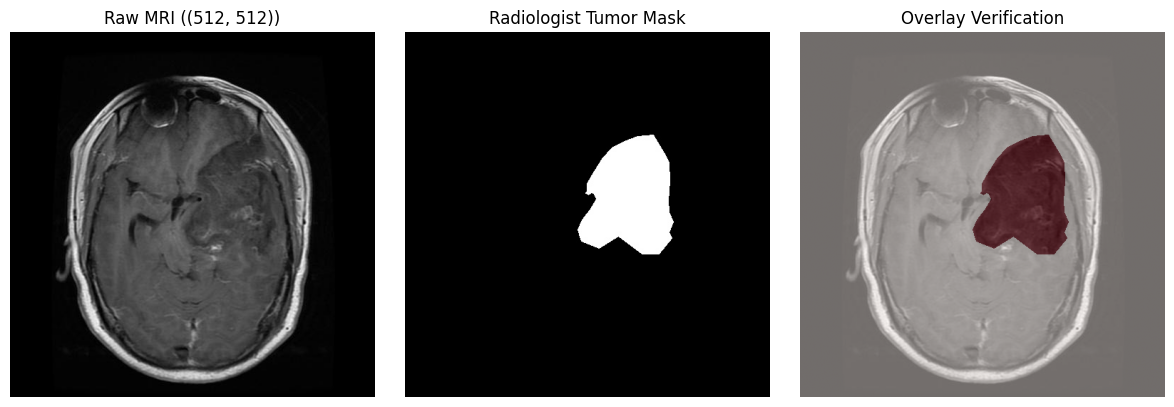

In [4]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = "/kaggle/input/brisc2025/brisc2025"

# 1. Check what is inside the main dataset folder
print("Main contents:", os.listdir(DATA_DIR))

# 2. Grab the very first training MRI image and its matching radiologist tumor mask
sample_img_path = sorted(glob.glob(f"{DATA_DIR}/segmentation_task/train/images/*.jpg"))[0]
sample_name = os.path.basename(sample_img_path)
sample_mask_path = f"{DATA_DIR}/segmentation_task/train/masks/{sample_name.replace('.jpg', '.png')}"

print("Sample filename:", sample_name)

# 3. Load and display them side-by-side
img = Image.open(sample_img_path)
mask = Image.open(sample_mask_path)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img, cmap="gray")
axes[0].set_title(f"Raw MRI ({img.size})")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Radiologist Tumor Mask")
axes[1].axis("off")

axes[2].imshow(img, cmap="gray")
axes[2].imshow(mask, cmap="Reds", alpha=0.45)  # Overlay the mask in red
axes[2].set_title("Overlay Verification")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [5]:
import pandas as pd

DATA_DIR = "/kaggle/input/brisc2025/brisc2025"
manifest = pd.read_csv(f"{DATA_DIR}/manifest.csv")

print("Total rows in manifest:", len(manifest))
print("\nColumns:", list(manifest.columns))
print("\nRows per task and split:")
print(pd.crosstab(manifest["task"], manifest["split"]))

print("\nFirst 5 rows:")
manifest.head()

Total rows in manifest: 15586

Columns: ['relative_path', 'filename', 'task', 'split', 'index', 'tumor_code', 'tumor_label', 'plane_code', 'plane_label', 'sequence', 'is_mask', 'linked_image', 'width', 'height', 'file_size_bytes', 'sha256']

Rows per task and split:
split           test  train
task                       
classification  1000   5000
segmentation    1720   7866

First 5 rows:


,relative_path,filename,task,split,index,tumor_code,tumor_label,plane_code,plane_label,sequence,is_mask,linked_image,width,height,file_size_bytes,sha256
0,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00001_gl_ax_t1.jpg,classification,test,1,gl,glioma,ax,axial,T1,False,NaN,512,512,25826,b513a83f68e486f45159b004d356782e78284014532151...
1,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00002_gl_ax_t1.jpg,classification,test,2,gl,glioma,ax,axial,T1,False,NaN,512,512,20982,5b4e4a0f482cb68955c340205d475f25c3a30718bd3b48...
2,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00003_gl_ax_t1.jpg,classification,test,3,gl,glioma,ax,axial,T1,False,NaN,512,512,13285,6fd1918b39e7a7f92fa5652d7802583f3251fed50a23ec...
3,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00004_gl_ax_t1.jpg,classification,test,4,gl,glioma,ax,axial,T1,False,NaN,512,512,26137,216b65a45d7effb4ebce1c9893f97d12449c9da777f818...
4,classification_task\test\glioma\brisc2025_test...,brisc2025_test_00005_gl_ax_t1.jpg,classification,test,5,gl,glioma,ax,axial,T1,False,NaN,512,512,21709,c35734545021ab5a4f55fb87e08732e26fb16abe887927...


In [6]:
import os
import pandas as pd

DATA_DIR = "/kaggle/input/brisc2025/brisc2025"
manifest = pd.read_csv(f"{DATA_DIR}/manifest.csv")

# 1. Fix Windows '\' slashes to Linux '/' slashes so Colab can open every file
manifest["full_path"] = manifest["relative_path"].str.replace("\\", "/", regex=False).apply(
    lambda p: os.path.join(DATA_DIR, p)
)

# 2. Take the 6,000 classification images (all 4 classes: glioma, meningioma, pituitary, no_tumor)
images_df = manifest[manifest["task"] == "classification"].copy()

# 3. Grab the segmentation masks (is_mask == True) and map them by filename stem
masks_df = manifest[(manifest["task"] == "segmentation") & (manifest["is_mask"] == True)].copy()
masks_df["stem"] = masks_df["filename"].str.replace(".png", "", regex=False)
mask_lookup = dict(zip(masks_df["stem"], masks_df["full_path"]))

# 4. Attach the matching mask path to each of the 6,000 scans
images_df["stem"] = images_df["filename"].str.replace(".jpg", "", regex=False)
images_df["mask_path"] = images_df["stem"].map(mask_lookup).fillna("")
images_df["has_mask"] = images_df["mask_path"] != ""

# 5. Keep only the clean columns we need and verify every single file exists on disk
master_df = images_df[[
    "filename", "stem", "split", "tumor_code", "tumor_label",
    "plane_code", "plane_label", "width", "height", "sha256",
    "full_path", "mask_path", "has_mask"
]].rename(columns={"full_path": "image_path"}).reset_index(drop=True)

missing_imgs = (~master_df["image_path"].apply(os.path.exists)).sum()
missing_masks = (~master_df[master_df["has_mask"]]["mask_path"].apply(os.path.exists)).sum()

print(f"Master table ready: {len(master_df)} scans")
print(f"Missing image files: {missing_imgs} | Missing mask files: {missing_masks}")
print("\nClass breakdown (with vs without mask):")
print(pd.crosstab(master_df["tumor_label"], master_df["has_mask"]))

Master table ready: 6000 scans
Missing image files: 0 | Missing mask files: 0

Class breakdown (with vs without mask):
has_mask     False  True 
tumor_label              
glioma           0   1401
meningioma       0   1635
no_tumor      1207      0
pituitary        0   1757


In [7]:
!pip install -q imagehash

import numpy as np
import imagehash
from PIL import Image
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

# 1. Compute a 64-bit perceptual fingerprint for each of the 6,000 MRI slices (~4 seconds)
hashes = []
for path in master_df["image_path"]:
    with Image.open(path) as img:
        hashes.append(imagehash.phash(img.convert("L"), hash_size=8))

hash_matrix = np.array([h.hash.flatten() for h in hashes], dtype=np.float32)

# 2. Compute pairwise Hamming distance (how many bits differ between every pair of MRIs)
row_sums = hash_matrix.sum(axis=1, keepdims=True)
hamming_dist = row_sums + row_sums.T - 2.0 * (hash_matrix @ hash_matrix.T)

# 3. Group slices with <= 6 differing bits into the same "pseudo_patient_id" cluster
adj = (hamming_dist <= 6).astype(np.int8)
n_clusters, cluster_ids = connected_components(csr_matrix(adj), directed=False)
master_df["pseudo_patient_id"] = cluster_ids

# 4. Check how many pseudo-patients appear in BOTH official train and official test
split_counts = master_df.groupby("pseudo_patient_id")["split"].nunique()
leaked_clusters = split_counts[split_counts > 1].index
leaked_test_rows = master_df[(master_df["split"] == "test") & (master_df["pseudo_patient_id"].isin(leaked_clusters))]

print(f"Total pseudo-patient clusters found: {n_clusters} (across 6,000 slices)")
print(f"Clusters leaking across BOTH official train & test: {len(leaked_clusters)}")
print(f"Official test images with a near-duplicate in train: {len(leaked_test_rows)} / 1000")

# 5. Create TWO clean benchmark splits:
#    - 'official_val_split': Keeps the official 1,000 test set untouched, and splits the 5,000 train set
#      into 4,000 train + 1,000 validation/calibration WITHOUT any cluster leakage between train and val.
#    - 'strict_split': Zero cluster leakage across train (3,600), val_cal (1,200), and test (1,200).
master_df["strat_key"] = master_df["tumor_label"] + "_" + master_df["plane_code"]

train_only = master_df[master_df["split"] == "train"].copy().reset_index(drop=True)
sgkf_5 = StratifiedGroupKFold(n_splits=5)
train_only["val_fold"] = -1
for fold, (_, v_idx) in enumerate(sgkf_5.split(train_only, train_only["strat_key"], train_only["pseudo_patient_id"])):
    train_only.loc[v_idx, "val_fold"] = fold

train_only["official_protocol"] = np.where(train_only["val_fold"] == 0, "val_cal", "train")
test_only = master_df[master_df["split"] == "test"].copy()
test_only["val_fold"] = -1
test_only["official_protocol"] = "test"

clean_df = pd.concat([train_only, test_only], ignore_index=True)

# Strict leak-free 5-fold split across all 6,000 scans
clean_df["strict_fold"] = -1
for fold, (_, v_idx) in enumerate(sgkf_5.split(clean_df, clean_df["strat_key"], clean_df["pseudo_patient_id"])):
    clean_df.loc[v_idx, "strict_fold"] = fold

clean_df["strict_protocol"] = clean_df["strict_fold"].map({0: "test", 1: "val_cal", 2: "train", 3: "train", 4: "train"})

clean_df.to_csv("/content/brisc2025_clean.csv", index=False)
print("\nSaved master manifest to /content/brisc2025_clean.csv")
print("Strict leak-free split counts:\n", clean_df["strict_protocol"].value_counts())

Total pseudo-patient clusters found: 3650 (across 6,000 slices)
Clusters leaking across BOTH official train & test: 420
Official test images with a near-duplicate in train: 559 / 1000

Saved master manifest to /content/brisc2025_clean.csv
Strict leak-free split counts:
 strict_protocol
train      3599
test       1201
val_cal    1200
Name: count, dtype: int64


In [8]:
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
import random
import numpy as np
import pandas as pd
from PIL import Image

CLASS_TO_IDX = {"glioma": 0, "meningioma": 1, "pituitary": 2, "no_tumor": 3}
PLANE_TO_IDX = {"ax": 0, "co": 1, "sa": 2}

class BRISCMultiTaskDataset(Dataset):
    def __init__(self, df, img_size=256, is_train=True):
        self.df = df.reset_index(drop=True)
        self.img_size = img_size
        self.is_train = is_train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # 1. Load grayscale MRI and resize to 256x256
        img = Image.open(row["image_path"]).convert("L")
        img = img.resize((self.img_size, self.img_size), resample=Image.BILINEAR)

        # 2. Load tumor mask (or create an all-black mask for healthy 'no_tumor' brains)
        if row["has_mask"]:
            mask = Image.open(row["mask_path"]).convert("L")
            mask = mask.resize((self.img_size, self.img_size), resample=Image.NEAREST)
        else:
            mask = Image.new("L", (self.img_size, self.img_size), 0)

        # 3. Synchronized data augmentation (training only)
        if self.is_train:
            if random.random() > 0.5:
                img = TF.hflip(img)
                mask = TF.hflip(mask)
            if random.random() > 0.5:
                angle = random.uniform(-15, 15)
                img = TF.rotate(img, angle)
                mask = TF.rotate(mask, angle)

        # 4. Convert to PyTorch tensors
        # Repeat 1 grayscale channel -> 3 channels so pretrained vision backbones work natively
        img_tensor = TF.to_tensor(img).repeat(3, 1, 1)
        img_tensor = TF.normalize(img_tensor, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

        # Binary mask: 1.0 where tumor exists, 0.0 everywhere else
        mask_tensor = (TF.to_tensor(mask) > 0.5).float()

        label_tensor = torch.tensor(CLASS_TO_IDX[row["tumor_label"]], dtype=torch.long)
        plane_tensor = torch.tensor(PLANE_TO_IDX[row["plane_code"]], dtype=torch.long)

        return img_tensor, mask_tensor, label_tensor, plane_tensor

# Load our strict leak-free split and test one batch
df = pd.read_csv("/content/brisc2025_clean.csv")
train_ds = BRISCMultiTaskDataset(df[df["strict_protocol"] == "train"], is_train=True)
val_ds   = BRISCMultiTaskDataset(df[df["strict_protocol"] == "val_cal"], is_train=False)
test_ds  = BRISCMultiTaskDataset(df[df["strict_protocol"] == "test"], is_train=False)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

# Sanity check: pull 1 batch and verify tensor shapes
imgs, masks, labels, planes = next(iter(train_loader))
print("Batch image shape:", imgs.shape)   # Expected: [16, 3, 256, 256]
print("Batch mask shape: ", masks.shape)  # Expected: [16, 1, 256, 256]
print("Batch labels:     ", labels[:8].tolist())
print("Batch planes:     ", planes[:8].tolist())

Batch image shape: torch.Size([16, 3, 256, 256])
Batch mask shape:  torch.Size([16, 1, 256, 256])
Batch labels:      [1, 0, 3, 3, 0, 3, 2, 1]
Batch planes:      [1, 1, 1, 2, 1, 0, 1, 2]


In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet34, ResNet34_Weights

class DecoderBlock(nn.Module):
    """Upsamples feature maps by 2x and fuses them with encoder skip connections."""
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        self.conv = nn.Sequential(
            nn.Conv2d(out_ch + skip_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Dropout2d(0.1),  # Enables MC-Dropout pixel uncertainty later
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x, skip=None):
        x = self.up(x)
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.conv(x)

class PlaneConditionedMultiTaskUNet(nn.Module):
    def __init__(self, num_classes=4, num_planes=3):
        super().__init__()
        backbone = resnet34(weights=ResNet34_Weights.DEFAULT)

        # Encoder stages (256 -> 128 -> 64 -> 32 -> 16 -> 8)
        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu)  # 64 ch, 128x128
        self.pool = backbone.maxpool                                            # 64 ch, 64x64
        self.enc1 = backbone.layer1                                             # 64 ch, 64x64
        self.enc2 = backbone.layer2                                             # 128 ch, 32x32
        self.enc3 = backbone.layer3                                             # 256 ch, 16x16
        self.enc4 = backbone.layer4                                             # 512 ch, 8x8

        # FiLM Plane Conditioning at the 512-channel bottleneck
        self.plane_emb = nn.Embedding(num_planes, 64)
        self.film = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(inplace=True),
            nn.Linear(256, 512 * 2)  # Outputs gamma (512) and beta (512)
        )

        # Head 1: 4-Class Tumor Classifier
        self.cls_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

        # Head 2: U-Net Segmentation Decoder (8 -> 16 -> 32 -> 64 -> 128 -> 256)
        self.dec4 = DecoderBlock(512, 256, 256)
        self.dec3 = DecoderBlock(256, 128, 128)
        self.dec2 = DecoderBlock(128, 64, 64)
        self.dec1 = DecoderBlock(64, 64, 32)
        self.final_up = nn.Sequential(
            nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, 1, kernel_size=1)
        )

    def forward(self, x, plane_idx):
        # 1. Encode MRI
        s0 = self.stem(x)            # [B, 64, 128, 128]
        s1 = self.enc1(self.pool(s0)) # [B, 64, 64, 64]
        s2 = self.enc2(s1)           # [B, 128, 32, 32]
        s3 = self.enc3(s2)           # [B, 256, 16, 16]
        bottleneck = self.enc4(s3)   # [B, 512, 8, 8]

        # 2. Condition bottleneck on Anatomical Plane (FiLM modulation)
        p_vec = self.plane_emb(plane_idx)
        gamma, beta = self.film(p_vec).chunk(2, dim=1)
        gamma = gamma.unsqueeze(-1).unsqueeze(-1)
        beta = beta.unsqueeze(-1).unsqueeze(-1)
        cond_feat = bottleneck * (1.0 + gamma) + beta

        # 3. Predict Class Logits & Segmentation Mask Logits simultaneously
        cls_logits = self.cls_head(cond_feat)
        d4 = self.dec4(cond_feat, s3)
        d3 = self.dec3(d4, s2)
        d2 = self.dec2(d3, s1)
        d1 = self.dec1(d2, s0)
        seg_logits = self.final_up(d1)

        return cls_logits, seg_logits

# Move model to T4 GPU and test a forward pass on our sample batch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PlaneConditionedMultiTaskUNet().to(device)

cls_out, seg_out = model(imgs.to(device), planes.to(device))
total_params = sum(p.numel() for p in model.parameters()) / 1e6

print(f"Running on device: {device}")
print(f"Total model parameters: {total_params:.2f}M")
print("Classifier output shape:", cls_out.shape)   # Expected: [16, 4]
print("Segmentation output shape:", seg_out.shape) # Expected: [16, 1, 256, 256]

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 178MB/s]


Running on device: cuda
Total model parameters: 24.63M
Classifier output shape: torch.Size([16, 4])
Segmentation output shape: torch.Size([16, 1, 256, 256])


In [10]:
import time
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import f1_score

def dice_bce_loss(seg_logits, targets, smooth=1e-5):
    bce = nn.functional.binary_cross_entropy_with_logits(seg_logits, targets)
    probs = torch.sigmoid(seg_logits)
    intersection = (probs * targets).sum(dim=(1, 2, 3))
    union = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    dice = (2.0 * intersection + smooth) / (union + smooth)
    return 0.5 * bce + 0.5 * (1.0 - dice.mean())

def compute_tumor_dice(seg_logits, targets, labels, smooth=1e-5):
    """Computes Dice similarity specifically on tumor-positive scans (labels != 3)."""
    tumor_mask = (labels != 3)
    if tumor_mask.sum() == 0:
        return []
    preds = (torch.sigmoid(seg_logits[tumor_mask]) > 0.5).float()
    targs = targets[tumor_mask]
    inter = (preds * targs).sum(dim=(1, 2, 3))
    union = preds.sum(dim=(1, 2, 3)) + targs.sum(dim=(1, 2, 3))
    dices = ((2.0 * inter + smooth) / (union + smooth)).cpu().tolist()
    return dices

# Re-initialize a fresh model so training starts cleanly from Epoch 1
torch.manual_seed(42)
model = PlaneConditionedMultiTaskUNet().to(device)

cls_criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
EPOCHS = 12
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda")

best_score = 0.0
print("Starting training on strict leak-free split (3,599 train / 1,200 val)...\n")

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    train_loss = 0.0

    for imgs, masks, labels, planes in train_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        labels, planes = labels.to(device), planes.to(device)

        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):
            cls_logits, seg_logits = model(imgs, planes)
            loss_cls = cls_criterion(cls_logits, labels)
            loss_seg = dice_bce_loss(seg_logits, masks)
            loss = loss_cls + 1.5 * loss_seg  # Slightly higher weight on pixel segmentation

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        train_loss += loss.item() * imgs.size(0)

    scheduler.step()
    train_loss /= len(train_ds)

    # Validation pass (strictly unseen pseudo-patients)
    model.eval()
    val_preds, val_targets, val_dices = [], [], []
    with torch.no_grad():
        for imgs, masks, labels, planes in val_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            labels, planes = labels.to(device), planes.to(device)
            with torch.amp.autocast("cuda"):
                cls_logits, seg_logits = model(imgs, planes)
            val_preds.extend(cls_logits.argmax(dim=1).cpu().tolist())
            val_targets.extend(labels.cpu().tolist())
            val_dices.extend(compute_tumor_dice(seg_logits, masks, labels))

    val_f1 = f1_score(val_targets, val_preds, average="macro")
    val_dice = float(np.mean(val_dices))
    combined_score = 0.5 * val_f1 + 0.5 * val_dice

    saved_tag = ""
    if combined_score > best_score:
        best_score = combined_score
        torch.save(model.state_dict(), "/content/best_brisc_model.pt")
        saved_tag = "  <-- Saved Best Model"

    print(f"Epoch {epoch:02d}/{EPOCHS:02d} ({time.time()-t0:.1f}s) | "
          f"Train Loss: {train_loss:.4f} | Val Macro-F1: {val_f1:.4f} | "
          f"Val Tumor Dice: {val_dice:.4f}{saved_tag}")

Starting training on strict leak-free split (3,599 train / 1,200 val)...

Epoch 01/12 (37.5s) | Train Loss: 1.4752 | Val Macro-F1: 0.8957 | Val Tumor Dice: 0.0000  <-- Saved Best Model
Epoch 02/12 (33.9s) | Train Loss: 0.9316 | Val Macro-F1: 0.9633 | Val Tumor Dice: 0.0000  <-- Saved Best Model
Epoch 03/12 (32.4s) | Train Loss: 0.7890 | Val Macro-F1: 0.9736 | Val Tumor Dice: 0.7803  <-- Saved Best Model
Epoch 04/12 (41.7s) | Train Loss: 0.7051 | Val Macro-F1: 0.9641 | Val Tumor Dice: 0.8089  <-- Saved Best Model
Epoch 05/12 (33.0s) | Train Loss: 0.6639 | Val Macro-F1: 0.9740 | Val Tumor Dice: 0.8105  <-- Saved Best Model
Epoch 06/12 (33.5s) | Train Loss: 0.6224 | Val Macro-F1: 0.9886 | Val Tumor Dice: 0.8257  <-- Saved Best Model
Epoch 07/12 (32.8s) | Train Loss: 0.5944 | Val Macro-F1: 0.9815 | Val Tumor Dice: 0.8300
Epoch 08/12 (33.5s) | Train Loss: 0.5772 | Val Macro-F1: 0.9884 | Val Tumor Dice: 0.8388  <-- Saved Best Model
Epoch 09/12 (32.9s) | Train Loss: 0.5519 | Val Macro-F1: 0.9

In [11]:
import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import classification_report, f1_score, accuracy_score

IDX_TO_CLASS = {0: "glioma", 1: "meningioma", 2: "pituitary", 3: "no_tumor"}

# 1. Load the best saved checkpoint
model.load_state_dict(torch.load("/content/best_brisc_model.pt", map_location=device))
model.eval()

def get_predictions(loader):
    all_probs, all_labels, all_dices, all_ious, healthy_fp_pixels = [], [], [], [], []
    with torch.no_grad():
        for imgs, masks, labels, planes in loader:
            imgs, masks = imgs.to(device), masks.to(device)
            labels, planes = labels.to(device), planes.to(device)
            cls_logits, seg_logits = model(imgs, planes)

            probs = F.softmax(cls_logits, dim=1).cpu().numpy()
            all_probs.append(probs)
            all_labels.extend(labels.cpu().tolist())

            preds_bin = (torch.sigmoid(seg_logits) > 0.5).float()
            for i in range(imgs.size(0)):
                if labels[i].item() != 3:  # Tumor scan
                    p = preds_bin[i]
                    t = masks[i]
                    inter = (p * t).sum().item()
                    union_dice = p.sum().item() + t.sum().item()
                    union_iou = ((p + t) > 0).float().sum().item()
                    all_dices.append((2.0 * inter + 1e-5) / (union_dice + 1e-5))
                    all_ious.append((inter + 1e-5) / (union_iou + 1e-5))
                else:  # Healthy 'no_tumor' scan: check if model falsely draws >10 tumor pixels
                    fp_px = preds_bin[i].sum().item()
                    healthy_fp_pixels.append(fp_px)

    return (
        np.vstack(all_probs),
        np.array(all_labels),
        float(np.mean(all_dices)),
        float(np.mean(all_ious)),
        healthy_fp_pixels,
    )

# 2. Run on Validation/Calibration set first to calibrate Split Conformal Prediction (alpha = 0.05 -> 95% coverage)
val_probs, val_labels, _, _, _ = get_predictions(val_loader)
alpha = 0.05
n_cal = len(val_labels)
cal_scores = 1.0 - val_probs[np.arange(n_cal), val_labels]
q_level = np.ceil((n_cal + 1) * (1.0 - alpha)) / n_cal
q_hat = float(np.quantile(cal_scores, q_level, method="higher"))

# 3. Run on completely unseen Test Set (1,201 scans)
test_probs, test_labels, test_dice, test_iou, healthy_fps = get_predictions(test_loader)
test_preds = test_probs.argmax(axis=1)

# Build Conformal Prediction Sets for every test scan
pred_sets = [np.where(p >= (1.0 - q_hat))[0].tolist() for p in test_probs]
empirical_coverage = np.mean([test_labels[i] in pred_sets[i] for i in range(len(test_labels))])
avg_set_size = np.mean([len(s) for s in pred_sets])
ambiguous_cases = sum(len(s) > 1 for s in pred_sets)

print("================ HELD-OUT TEST SET REPORT (1,201 UNSEEN SCANS) ================")
print(f"Test Accuracy:              {accuracy_score(test_labels, test_preds):.4f}")
print(f"Test Macro-F1:              {f1_score(test_labels, test_preds, average='macro'):.4f}")
print(f"Test Tumor Dice Score:      {test_dice:.4f}")
print(f"Test Tumor IoU Score:       {test_iou:.4f}")
print(f"Healthy Brain False-Alarms: {sum(px > 10 for px in healthy_fps)} / {len(healthy_fps)} scans")
print("-------------------------------------------------------------------------------")
print(f"Conformal Threshold (q_hat):       {q_hat:.4f} (Target Coverage: 95.0%)")
print(f"Empirical Conformal Coverage:      {empirical_coverage*100:.2f}%")
print(f"Average Prediction Set Size:       {avg_set_size:.3f} classes")
print(f"Flagged Ambiguous Scans (|Set|>1): {ambiguous_cases} / {len(test_labels)}")
print("===============================================================================\n")
print(classification_report(test_labels, test_preds, target_names=["glioma", "meningioma", "pituitary", "no_tumor"], digits=4))

================ HELD-OUT TEST SET REPORT (1,201 UNSEEN SCANS) ================
Test Accuracy:              0.9958
Test Macro-F1:              0.9958
Test Tumor Dice Score:      0.8401
Test Tumor IoU Score:       0.7573
Healthy Brain False-Alarms: 6 / 242 scans
-------------------------------------------------------------------------------
Conformal Threshold (q_hat):       0.0579 (Target Coverage: 95.0%)
Empirical Conformal Coverage:      95.67%
Average Prediction Set Size:       0.958 classes
Flagged Ambiguous Scans (|Set|>1): 0 / 1201

              precision    recall  f1-score   support

      glioma     0.9964    0.9964    0.9964       280
  meningioma     0.9939    0.9939    0.9939       328
   pituitary     1.0000    0.9943    0.9971       351
    no_tumor     0.9918    1.0000    0.9959       242

    accuracy                         0.9958      1201
   macro avg     0.9955    0.9962    0.9958      1201
weighted avg     0.9959    0.9958    0.9958      1201



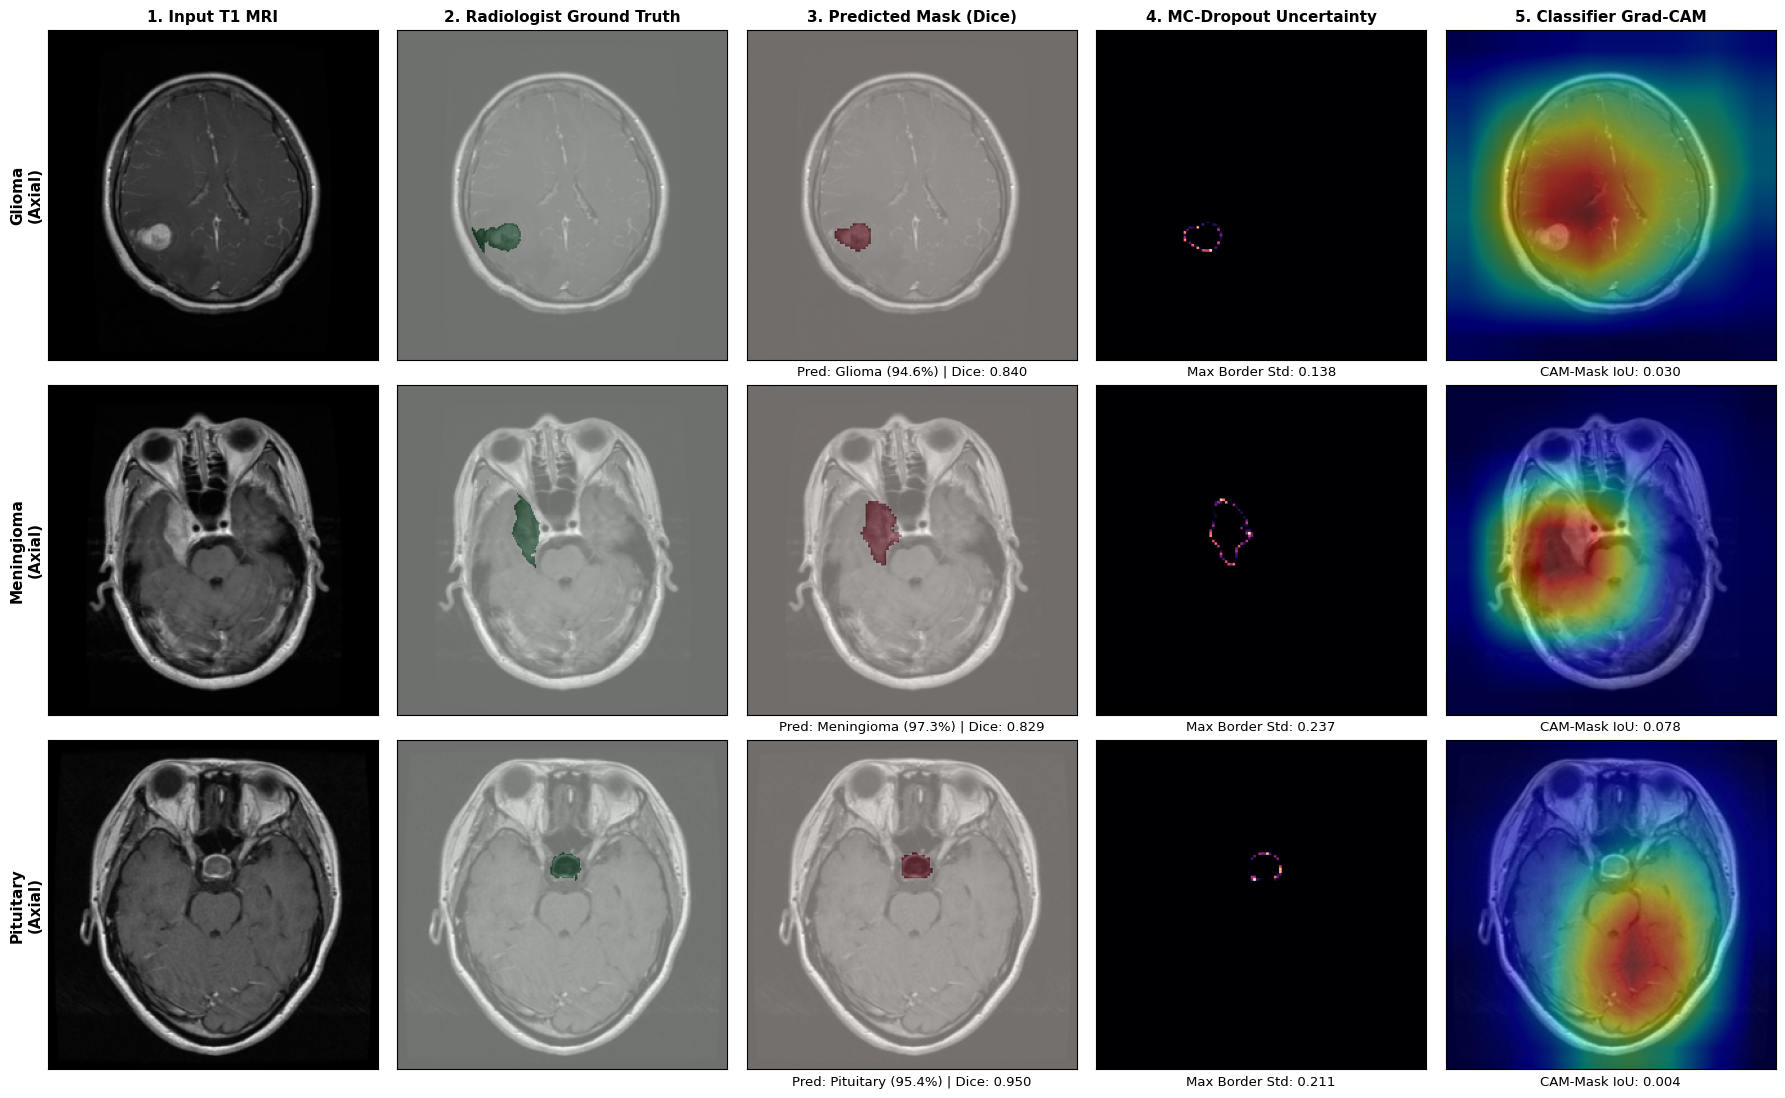

Saved high-resolution diagnostic figure to /content/brisc2025_clinical_diagnostics.png


In [12]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

IDX_TO_CLASS = {0: "Glioma", 1: "Meningioma", 2: "Pituitary", 3: "No Tumor"}
IDX_TO_PLANE = {0: "Axial", 1: "Coronal", 2: "Sagittal"}

def enable_mc_dropout(m):
    """Keeps BatchNorm in eval mode while turning Dropout2d ON for uncertainty sampling."""
    if isinstance(m, (torch.nn.Dropout, torch.nn.Dropout2d)):
        m.train()

def predict_with_uncertainty_and_cam(img_tensor, plane_tensor, target_class, n_passes=10):
    model.eval()
    x = img_tensor.unsqueeze(0).to(device).requires_grad_(True)
    p = plane_tensor.unsqueeze(0).to(device)

    # 1. Grad-CAM hook on the final encoder stage (enc4)
    activations, gradients = [], []
    fwd_hook = model.enc4.register_forward_hook(lambda _, __, out: activations.append(out))
    bwd_hook = model.enc4.register_full_backward_hook(lambda _, __, grad: gradients.append(grad[0]))

    cls_logits, _ = model(x, p)
    model.zero_grad()
    cls_logits[0, target_class].backward()
    fwd_hook.remove()
    bwd_hook.remove()

    weights = gradients[0].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * activations[0]).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=(256, 256), mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    # 2. Monte Carlo Dropout (10 stochastic forward passes for pixel uncertainty)
    model.apply(enable_mc_dropout)
    seg_samples, prob_samples = [], []
    with torch.no_grad():
        for _ in range(n_passes):
            c_out, s_out = model(x.detach(), p)
            prob_samples.append(torch.softmax(c_out, dim=1)[0].cpu().numpy())
            seg_samples.append(torch.sigmoid(s_out)[0, 0].cpu().numpy())

    model.eval()
    mean_probs = np.mean(prob_samples, axis=0)
    mean_mask = np.mean(seg_samples, axis=0)
    pixel_uncertainty = np.std(seg_samples, axis=0)  # Standard deviation across stochastic passes
    return mean_probs, mean_mask, pixel_uncertainty, cam

# Pick 1 test scan from each tumor class (Glioma=0, Meningioma=1, Pituitary=2)
test_ds = test_loader.dataset
sample_indices = []
for cls_id in [0, 1, 2]:
    for idx in range(len(test_ds)):
        if test_ds[idx][2].item() == cls_id:
            sample_indices.append(idx)
            break

fig, axes = plt.subplots(3, 5, figsize=(18, 11))
col_titles = [
    "1. Input T1 MRI",
    "2. Radiologist Ground Truth",
    "3. Predicted Mask (Dice)",
    "4. MC-Dropout Uncertainty",
    "5. Classifier Grad-CAM"
]

for row_idx, ds_idx in enumerate(sample_indices):
    img_t, mask_t, label_t, plane_t = test_ds[ds_idx]
    true_cls = label_t.item()
    plane_name = IDX_TO_PLANE[plane_t.item()]

    probs, pred_prob_mask, unc_map, cam_map = predict_with_uncertainty_and_cam(img_t, plane_t, true_cls)
    pred_cls = int(np.argmax(probs))
    pred_bin = (pred_prob_mask > 0.5).astype(np.float32)
    gt_bin = mask_t[0].numpy()

    # Dice & IoU-CAM alignment
    dice = (2.0 * (pred_bin * gt_bin).sum() + 1e-5) / (pred_bin.sum() + gt_bin.sum() + 1e-5)
    cam_bin = (cam_map > 0.5).astype(np.float32)
    cam_iou = ((cam_bin * gt_bin).sum() + 1e-5) / (((cam_bin + gt_bin) > 0).sum() + 1e-5)

    # Un-normalize MRI for display
    mri_disp = np.clip(img_t[0].numpy() * 0.229 + 0.485, 0, 1)

    axes[row_idx, 0].imshow(mri_disp, cmap="gray")
    axes[row_idx, 0].set_ylabel(f"{IDX_TO_CLASS[true_cls]}\n({plane_name})", fontsize=11, fontweight="bold")

    axes[row_idx, 1].imshow(mri_disp, cmap="gray")
    axes[row_idx, 1].imshow(gt_bin, cmap="Greens", alpha=0.45)

    axes[row_idx, 2].imshow(mri_disp, cmap="gray")
    axes[row_idx, 2].imshow(pred_bin, cmap="Reds", alpha=0.45)
    axes[row_idx, 2].set_xlabel(f"Pred: {IDX_TO_CLASS[pred_cls]} ({probs[pred_cls]*100:.1f}%) | Dice: {dice:.3f}", fontsize=9.5)

    axes[row_idx, 3].imshow(unc_map, cmap="magma")
    axes[row_idx, 3].set_xlabel(f"Max Border Std: {unc_map.max():.3f}", fontsize=9.5)

    axes[row_idx, 4].imshow(mri_disp, cmap="gray")
    axes[row_idx, 4].imshow(cam_map, cmap="jet", alpha=0.45)
    axes[row_idx, 4].set_xlabel(f"CAM-Mask IoU: {cam_iou:.3f}", fontsize=9.5)

    for c in range(5):
        axes[row_idx, c].set_xticks([])
        axes[row_idx, c].set_yticks([])
        if row_idx == 0:
            axes[row_idx, c].set_title(col_titles[c], fontsize=11, fontweight="bold")

plt.tight_layout()
plt.savefig("/content/brisc2025_clinical_diagnostics.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved high-resolution diagnostic figure to /content/brisc2025_clinical_diagnostics.png")